# Notebook 1: Exploratory Data Analysis and Feature Engineering

**Project:** Digital Publishing Opportunity Intelligence: which Kindle niches should a new author write for?

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

> Which Kindle book niches show growing reader demand, how open are they to less-known authors,
> and can the signals a book shows in its first 90 days predict whether it will succeed within its niche?

In this notebook I look at the original data, take a sample of 200,000 books rated between 2019 and 2023, clean it,
join the tables, explore it with charts and create the features for the prediction model in Notebook 2.

**Suggestions from mentors.** Because the original files are very large, my mentors suggested **Polars**, which can count
what is inside a huge file without loading it; I use it in Part 1. For reading reviews they suggested **BERT**, a language
model that understands whole sentences, run with **Hugging Face Transformers** and **PyTorch**; I use it in Part 5 to mark
reviews as positive or negative. My first plan, **VADER**, a simpler word-based tool, is kept for a comparison in Notebook 2.

**Contents**

1. The original data
2. The working sample
3. Cleaning
4. Joining the tables
5. Exploratory data analysis

---
# Part 1: The original data

## Step 1: Libraries and folders

I load the libraries and tell the notebook where the data is.

- `pandas` works with tables; `polars` can describe huge files without loading them.
- `matplotlib` and `seaborn` draw charts.
- `PROJECT` finds the project folder, whether the notebook starts in `notebooks/` or in the project folder.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT / "data" / "raw"
RAW_SAMPLE = PROJECT / "data" / "raw_sample"
CLEAN = PROJECT / "data" / "clean"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# One chart style for the whole notebook
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
FOCUS_NICHES = ["Children's eBooks", "Education & Teaching", "Teen & Young Adult", "Parenting & Relationships"]
DAY_MS = 24 * 60 * 60 * 1000   # one day in milliseconds

print("Project folder:", PROJECT)

Project folder: C:\Users\Korisnik\Desktop\Data Science Bootcamp\Capstone


## Step 2: The original datasets in one table

I use two sources: a **Kaggle** snapshot of Kindle books with bestseller labels, and the **Amazon Reviews 2023** data
for the Kindle Store, which has every rating and review with its date. The Amazon files are too large for pandas (up to
15 GB), so I count their rows and columns with **Polars** in *lazy* mode: `scan_csv()` and `scan_ndjson()` only read what
is needed for the count. This cell takes about two minutes because Polars reads through 22 GB of data.

In [2]:
def describe_file(name, lazy_frame, one_row):
    path = RAW / name
    return {
        "file": name,
        "size_GB": round(path.stat().st_size / 1024**3, 2),
        "rows": lazy_frame.select(pl.len()).collect().item(),
        "columns": len(lazy_frame.collect_schema()),
        "one row is": one_row,
    }

raw_overview = pd.DataFrame([
    describe_file("kindle_data-v2.csv", pl.scan_csv(RAW / "kindle_data-v2.csv"), "a book (Kaggle, with bestseller labels)"),
    describe_file("meta_Kindle_Store.jsonl",
                  pl.scan_ndjson(RAW / "meta_Kindle_Store.jsonl", infer_schema_length=None), "a book (details)"),
    describe_file("Kindle_Store_0core.csv", pl.scan_csv(RAW / "Kindle_Store_0core.csv"), "a rating"),
    describe_file("Kindle_Store_reviews.jsonl",
                  pl.scan_ndjson(RAW / "Kindle_Store_reviews.jsonl", infer_schema_length=None), "a review with text"),
])
raw_overview

,file,size_GB,rows,columns,one row is
0,kindle_data-v2.csv,0.03,133102,16,"a book (Kaggle, with bestseller labels)"
1,meta_Kindle_Store.jsonl,6.39,1591371,16,a book (details)
2,Kindle_Store_0core.csv,1.37,25302305,4,a rating
3,Kindle_Store_reviews.jsonl,14.72,25577616,10,a review with text


Together the original data has about **22 GB**: 1.6 million books, 25.3 million ratings and 25.6 million reviews, from
1999 to September 2023. `infer_schema_length=None` tells Polars to look at all rows before deciding the column types,
because some fields are a number in one row and text in another.

To see what one row looks like, I open the small random samples of the original files that my script
`00_make_raw_samples.py` saved without any change.

In [3]:
meta_raw = pd.read_json(RAW_SAMPLE / "meta_Kindle_Store_sample.jsonl", lines=True)
meta_raw.head(3)

,main_category,title,subtitle,author,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,Buy a Kindle,The Kate Chronicles: Princess Katrina,Kindle Edition,{'avatar': 'https://m.media-amazon.com/images/S/amzn-aut...,5.0,1,"[Katrina Resmina Castian, crown princess of Armestel is ...",[],1.99,[{'large': 'https://m.media-amazon.com/images/I/51fNAmdU...,[],James Cole (Author) Format: Kindle Edition,"[Kindle Store, Kindle eBooks, Children's eBooks]","{'Publication date': 'December 7, 2020', 'Language': 'En...",B08PZLM5KV,NaN
1,Buy a Kindle,The Unearthly Tree,Kindle Edition,None,5.0,1,[The year is 1865 and it’s close to the end of the Civil...,[],0.0,[],[],Danny Drew (Author) Format: Kindle Edition,"[Kindle Store, Kindle eBooks, Literature & Fiction]","{'Publisher': 'Drews Publishing; 1st edition (July 13, 2...",B011LGCV0S,NaN
2,Buy a Kindle,True Ladies and Proper Gentlemen: Victorian Etiquette fo...,NaN,{'avatar': 'https://m.media-amazon.com/images/S/amzn-aut...,4.7,170,"[Regardless of time period, some things hold true: kindn...","[From the Author, Sarah A. Chrisman, is the author of, V...",9.99,[{'large': 'https://m.media-amazon.com/images/I/518xh72N...,[],"Sarah A. Chrisman (Author, Editor) Format: Kindle Edition","[Kindle Store, Kindle eBooks, History]","{'Publisher': 'Skyhorse; 1st edition (May 19, 2015)', 'P...",B00XAF9LHU,NaN


In [4]:
ratings_raw = pd.read_csv(RAW_SAMPLE / "Kindle_Store_0core_sample.csv")
ratings_raw.head(3)

,user_id,parent_asin,rating,timestamp
0,AEZ7TPXTPWD5DH4IVQVL46E4IHEA,B00CQC9O16,2.0,1627374217968
1,AH6M2YEQTIVZN43HPJXAA64DNIBA,B00CM04MSC,4.0,1389157834000
2,AFKK3F4VXDJWHHVC4FGAQ2YEFEYA,B09WGZ1XDX,2.0,1662982363945


A book row has 16 columns, and several of them are lists or dictionaries (`author`, `categories`, `details`, `images`).
A rating row is simple: user, book, stars and time in milliseconds. The **review** rows are the same events as the ratings,
with the text added.

The full analysis of the original files (missing values, duplicates, odd values in every column) is in
`notebooks/archive/01_EDA_detailed_research.ipynb`. Here I keep only what matters for the prediction.

---
# Part 2: The working sample

## Step 3: From 22 GB to a working sample

I made the data smaller with four scripts in the `scripts/` folder. They only choose rows and columns; every value stays
exactly as it was, so all cleaning happens in this notebook.

| What I kept | Why |
|---|---|
| ratings and reviews from **1 January 2019 to 13 September 2023** | recent enough to show today's market, long enough to see trends |
| a random sample of **200,000 books** rated in that period | enough books for every niche, small enough to work fast |
| 13 of the 16 book columns, for **all** books | an author's fame needs all books the author has written |
| the date of each book's **first rating ever** | a book's release date is often missing, the first rating shows when readers found it |
| all reviews from each sampled book's **first 90 days** | the early signals for the prediction |

Now I load the working files and keep only the 200,000 sampled books.

- `.isin()` checks whether a value is in a list; I use it to keep only the sampled books.

In [5]:
sample_ids = pd.read_parquet(CLEAN / "book_sample_ids.parquet")["parent_asin"]

books_all = pd.read_parquet(CLEAN / "meta_light.parquet")          # all books: needed later for author fame
books = books_all[books_all["parent_asin"].isin(sample_ids)].reset_index(drop=True)

ratings = pd.read_parquet(CLEAN / "ratings_2019_2023.parquet")
ratings = ratings[ratings["parent_asin"].isin(sample_ids)].reset_index(drop=True)

first_rating = pd.read_parquet(CLEAN / "book_first_rating.parquet")
first_rating = first_rating[first_rating["parent_asin"].isin(sample_ids)].reset_index(drop=True)

reviews_90 = pd.read_parquet(CLEAN / "reviews_first_90_days.parquet")

pd.DataFrame({
    "table": ["books", "ratings", "first_rating", "reviews_90"],
    "rows": [len(books), len(ratings), len(first_rating), len(reviews_90)],
    "columns": [books.shape[1], ratings.shape[1], first_rating.shape[1], reviews_90.shape[1]],
    "one row is": ["a sampled book", "a rating 2019-2023", "a book's first rating ever",
                   "a review in a book's first 90 days"],
})

,table,rows,columns,one row is
0,books,200000,13,a sampled book
1,ratings,2014383,4,a rating 2019-2023
2,first_rating,200000,3,a book's first rating ever
3,reviews_90,822258,9,a review in a book's first 90 days


The working sample has **200,000 books** with about **2 million ratings** from 2019–2023, and about 822,000 reviews from
the books' first 90 days. This is what I clean, explore and use for the model.

---
# Part 3: Cleaning

## Step 4: What the books table looks like

Before cleaning, I look at the books table as it is.

In [6]:
books.head(6)

,parent_asin,title,author_name,store,main_category,categories,average_rating,rating_number,price,publisher,publication_date,language,print_length
0,B00155EZRS,The Road Home,Jim Harrison,Jim Harrison (Author) Format: Kindle Edition,Buy a Kindle,"[Kindle Store, Kindle eBooks, Literature & Fiction]",4.5,475,10.44,"Atlantic Monthly Press (December 1, 2007)","December 1, 2007",English,466 pages
1,B08DV7XLXS,Reluctant Partners,J. L. Guin,J. L. Guin (Author) Format: Kindle Edition,Buy a Kindle,"[Kindle Store, Kindle Unlimited, Literature & Fiction]",4.5,7,0.0,"Sundown Press (August 12, 2020)","August 12, 2020",English,126 pages
2,B01EH4IUCE,Deadly Desserts (Sky High Pies Cozy Mysteries Book 6),Mary Maxwell,Mary Maxwell (Author) Format: Kindle Edition,Buy a Kindle,"[Kindle Store, Kindle eBooks, Mystery, Thriller & Suspense]",4.4,720,0.0,NaN,"April 18, 2016",English,197 pages
3,B01JDQ4LY2,THE MAN WITH ALL THE HONEY: Sweet & Dirty BBW MC Romance...,Cathryn Cade,Cathryn Cade (Author) Format: Kindle Edition,Buy a Kindle,"[Kindle Store, Kindle eBooks, Literature & Fiction]",4.6,353,0.0,"Windtree Press (July 29, 2016)","July 29, 2016",English,311 pages
4,B07QPQCZNQ,Garlic & Olive Oil: Bringing family together with food,Emily I. Vannoni,Emily I. Vannoni (Author) Format: Kindle Edition,Buy a Kindle,"[Kindle Store, Kindle eBooks, Cookbooks, Food & Wine]",4.9,27,9.99,NaN,"April 14, 2019",English,140 pages
5,B00O170I6O,LEAP INTO THE KNIGHT: Book One in the Romantic Knights T...,M.J. Schiller,"M.J. Schiller (Author), Laurie Larsen (Editor), Kather...",Buy a Kindle,"[Kindle Store, Kindle eBooks, Science Fiction & Fantasy]",4.3,8,0.0,"Kissmet Publishing (November 1, 2014)","November 1, 2014",English,136 pages


In [7]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   parent_asin       200000 non-null  str    
 1   title             200000 non-null  str    
 2   author_name       168114 non-null  str    
 3   store             199996 non-null  str    
 4   main_category     199984 non-null  str    
 5   categories        200000 non-null  object 
 6   average_rating    200000 non-null  float64
 7   rating_number     200000 non-null  int64  
 8   price             174954 non-null  str    
 9   publisher         119047 non-null  str    
 10  publication_date  192779 non-null  str    
 11  language          192853 non-null  str    
 12  print_length      186767 non-null  str    
dtypes: float64(1), int64(1), object(1), str(10)
memory usage: 58.2+ MB


The table is not ready for analysis. Looking at the rows and the types, I see these problems:

1. `author_name` is empty for some books, but the name is written in `store` (`"Name (Author) Format: …"`).
2. The niche (genre) is hidden inside the `categories` list.
3. `price` is text, not a number.
4. `print_length` is text like `"378 pages"`.
5. Some columns are not needed: `main_category` is almost always `"Buy a Kindle"`, and `average_rating` and
   `rating_number` are Amazon's totals from **2023**, so they contain the future of every book.

I fix them one by one. For each problem I first measure it, then fix it and show the result.

## Step 5: Remove the columns I do not need

First I check what is inside the columns I want to remove.

In [8]:
print(books["main_category"].value_counts(dropna=False))
print()
print("Missing publisher:", f"{books['publisher'].isna().mean():.0%}",
      "| Missing publication date:", f"{books['publication_date'].isna().mean():.0%}")

main_category
Buy a Kindle    195192
                  4792
NaN                 16
Name: count, dtype: int64

Missing publisher: 40% | Missing publication date: 4%


**Rule.** I remove a column if it has no information (`main_category`), if I replace it with something better
(`publication_date` → the date of the first rating; `publisher` is missing for many books), or if it would let the model
see the future (`average_rating` and `rating_number` were measured in 2023, after the books' first months). I also remove
`language`, because almost all books are in English.

- `.drop(columns=[...])` removes columns.

In [9]:
columns_to_remove = ["main_category", "publisher", "publication_date", "language", "average_rating", "rating_number"]

print("Columns before:", books.shape[1])
books = books.drop(columns=columns_to_remove)
print("Columns after: ", books.shape[1], "->", list(books.columns))

Columns before: 13
Columns after:  7 -> ['parent_asin', 'title', 'author_name', 'store', 'categories', 'price', 'print_length']


## Step 6: Recover missing authors from `store`

I count the books without an author and look at their `store` text.

In [10]:
no_author = books["author_name"].isna()
print("Books without author_name:", no_author.sum(), f"({no_author.mean():.1%})")
books.loc[no_author, ["title", "author_name", "store"]].head(6)

Books without author_name: 31886 (15.9%)


,title,author_name,store
8,Batman: Harley Quinn,NaN,"by Paul Dini (Author), Neil Googe (Il..."
18,"PEDAGOGÍA : Educación, Enseñanza y Aprendizaje a todo ni...",NaN,Spanish Edition Amparo Aurora Ram...
23,DC Graphic Novels for Young Adults Sneak Previews: Super...,NaN,"by Gene Luen Yang (Author), Gurihiru ..."
28,All-New Wolverine (2015-2018) Annual #1,NaN,"by Tom Taylor (Author), Cameron Stewar..."
45,Angelbound Offspring Box Set (Books 1-5),NaN,Christina Bauer (Author) Format: Kindle Edition
52,A Changing Tide: The Rise of the Elindari (The Elindari ...,NaN,Jeff W Long (Author) Format: Kindle Edition


The name is in `store`, just before `(Author`. The text comes in several forms: one author, several people separated by
commas, a second role like `(Author, Editor)`, or other words before the name (`"by"`, `"Spanish Edition"`) separated by
many spaces.

**Rule.** If `author_name` is empty, I take the text before the first `(Author`, keep only the part after the last comma,
and then only the part after the last group of 2 or more spaces. If `store` has no `(Author`, the author stays empty.

- `re.split(r"\s{2,}", text)` splits a text wherever there are 2 or more spaces in a row.
- `.fillna()` fills empty cells with values from another column.

In [11]:
def author_from_store(store):
    # "by    Mike Mignola  (Author),  Various (Illustrator) ..." -> "Mike Mignola"
    if not isinstance(store, str) or "(Author" not in store:
        return None
    before = store.split("(Author")[0]          # text before the first "(Author"
    before = before.split(",")[-1].strip()      # if several people: the last one before "(Author"
    name = re.split(r"\s{2,}", before)[-1]      # drop words like "by" or "Spanish Edition" before many spaces
    return name.strip() or None

# Test the rule on the different forms
for example in ["Kent Rodgers (Author)   Format: Kindle Edition",
                "by              Mike Mignola  (Author),     Various  (Illustrator)    Format: Kindle Edition",
                "Sarah A. Chrisman (Author, Editor)   Format: Kindle Edition",
                "Spanish Edition                          Katty Llinas (Author)   Format: Kindle Edition"]:
    print(f"{author_from_store(example)!r:22} <- {example[:70]}")

'Kent Rodgers'         <- Kent Rodgers (Author)   Format: Kindle Edition
'Mike Mignola'         <- by              Mike Mignola  (Author),     Various  (Illustrator)    
'Sarah A. Chrisman'    <- Sarah A. Chrisman (Author, Editor)   Format: Kindle Edition
'Katty Llinas'         <- Spanish Edition                          Katty Llinas (Author)   Forma


In [12]:
books["author"] = books["author_name"].fillna(books["store"].apply(author_from_store))

print("Books without an author before:", books["author_name"].isna().sum())
print("Books without an author after: ", books["author"].isna().sum(), f"({books['author'].isna().mean():.1%})")
books.loc[no_author, ["store", "author"]].head(6)

Books without an author before: 31886
Books without an author after:  320 (0.2%)


,store,author
8,"by Paul Dini (Author), Neil Googe (Il...",Paul Dini
18,Spanish Edition Amparo Aurora Ram...,Amparo Aurora Ramírez Tamayo
23,"by Gene Luen Yang (Author), Gurihiru ...",Gene Luen Yang
28,"by Tom Taylor (Author), Cameron Stewar...",Tom Taylor
45,Christina Bauer (Author) Format: Kindle Edition,Christina Bauer
52,Jeff W Long (Author) Format: Kindle Edition,Jeff W Long


The rule works on all four forms. Almost every missing author is now recovered: only a few hundred books (about 0.4%)
remain without an author, because their `store` does not name one. I keep the new `author` column and remove the two
old ones.

In [13]:
books = books.drop(columns=["author_name", "store"])

## Step 7: Extract the niche from `categories`

`categories` is a list such as `['Kindle Store', 'Kindle eBooks', 'Romance']`. The niche is the 3rd element. I look at the
2nd element first, because only the `Kindle eBooks` branch has real genres at the 3rd level.

In [14]:
second_level = books["categories"].apply(lambda c: c[1] if len(c) > 1 else None)
third_level = books["categories"].apply(lambda c: c[2] if len(c) > 2 else None)

print(second_level.value_counts().head(6))
print()
print("Examples of 3rd-level values outside 'Kindle eBooks':")
print(third_level[second_level != "Kindle eBooks"].value_counts().head(6))

categories
Kindle eBooks              197004
Kindle Unlimited             2126
Kindle Short Reads            556
Kindle eTextbooks             183
Religion & Spirituality       113
Whispersync for Voice          15
Name: count, dtype: int64

Examples of 3rd-level values outside 'Kindle eBooks':
categories
Religion & Spirituality             653
Professional & Technical            635
Two hours or more (65-100 pages)    237
Literature & Fiction                193
Children's eBooks                   183
Medicine & Health Sciences          169
Name: count, dtype: int64


Almost all books are under `Kindle eBooks`. In other branches the 3rd level can be a genre (like `Children's eBooks`
under `Kindle Unlimited`) or something else (like a reading time under `Kindle Short Reads`).

**Rule.** The genres are the 3rd-level values under `Kindle eBooks`. A book gets a niche if its 3rd level is one of these
genres; otherwise it has no niche and is removed, because the whole project compares books **within** a niche.

In [15]:
genres = set(third_level[second_level == "Kindle eBooks"].dropna())
books["niche"] = third_level.where(third_level.isin(genres))

print("Genres:", len(genres))
print("Books without a niche:", books["niche"].isna().sum())

books = books[books["niche"].notna()].drop(columns=["categories"]).reset_index(drop=True)
print("Books left:", len(books))

Genres: 31
Books without a niche: 1745
Books left: 198255


Some niches have very few books, and comparing a book with the top 25% of a niche needs enough books in that niche.

In [16]:
niche_sizes = books["niche"].value_counts()
niche_sizes.tail(8)

niche
Foreign Languages               762
Engineering & Transportation    684
Parenting & Relationships       655
Self-Help                       433
Nonfiction                      382
Medical eBooks                  325
Law                             185
LGBTQ+ eBooks                    30
Name: count, dtype: int64

**Rule.** Niches with fewer than 500 books in the sample are merged into one group called `Other`. The four niches of my
hypothesis (children, education, teens, parenting) all have more than 500 books and stay separate.

In [17]:
small_niches = niche_sizes[niche_sizes < 500].index.tolist()
print("Merged into 'Other':", small_niches)

books["niche"] = books["niche"].where(~books["niche"].isin(small_niches), "Other")
print("Niches before:", len(niche_sizes), "| after:", books["niche"].nunique())

Merged into 'Other': ['Self-Help', 'Nonfiction', 'Medical eBooks', 'Law', 'LGBTQ+ eBooks']
Niches before: 31 | after: 27


## Step 8: Turn the price into a number

I try to convert every price to a number and look at the ones that fail.

- `pd.to_numeric(..., errors="coerce")` gives an empty value when the text is not a number.

In [18]:
price_number = pd.to_numeric(books["price"], errors="coerce")
failed = price_number.isna() & books["price"].notna()

print("Prices that are not a number:", failed.sum())
books.loc[failed, "price"].value_counts().head(6)

Prices that are not a number: 557


price
—            242
from 2.99     71
from 9.99     32
from 0.99     32
from 4.99     17
from 3.99     17
Name: count, dtype: int64

**Rule.** A dash `"—"` means the price is unknown, so it becomes empty. `"from 2.99"` means the cheapest offer is 2.99,
so I keep the number after `"from"`.

In [19]:
books["price"] = pd.to_numeric(
    books["price"].replace("—", None).str.replace("from ", "", regex=False),
    errors="coerce",
)

print("Price type now:", books["price"].dtype)
print("Empty prices:", books["price"].isna().sum())
books["price"].describe().round(2)

Price type now: float64
Empty prices: 25081


count    173174.00
mean          3.66
std           6.88
min           0.00
25%           0.00
50%           0.00
75%           4.99
max         375.56
Name: price, dtype: float64

The price is now a number. More than half of the books cost **0** (free Kindle books and promotions), so the median price
is 0; a quarter of the books cost 4.99 dollars or more, and the most expensive one costs 375.56. Missing prices stay empty.

## Step 9: Turn the print length into a number

`print_length` looks like `"378 pages"`. I check that every value has this form, then keep only the number.

- `.str.extract(r"(\d+)")` takes the first number out of a text.

In [20]:
print("Values not in the form '<number> pages':",
      (~books["print_length"].str.fullmatch(r"[\d,]+ pages", na=True)).sum())

books["pages"] = pd.to_numeric(books["print_length"].str.replace(",", "").str.extract(r"(\d+)")[0])
books = books.drop(columns=["print_length"])

books["pages"].describe().round(0)

Values not in the form '<number> pages': 0


count    185151.0
mean        262.0
std         413.0
min           0.0
25%         130.0
50%         232.0
75%         328.0
max       81612.0
Name: pages, dtype: float64

## Step 10: Turn milliseconds into dates

Times in the ratings, reviews and first-rating tables are numbers of milliseconds since 1970. I convert them to dates.

- `pd.to_datetime(..., unit="ms")` turns milliseconds into a date and time.

In [21]:
print("Before:", ratings["timestamp"].iloc[0])

ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="ms")
reviews_90["date"] = pd.to_datetime(reviews_90["timestamp"], unit="ms")
first_rating["first_rating_date"] = pd.to_datetime(first_rating["first_rating_ts"], unit="ms")

print("After: ", ratings["date"].iloc[0])

Before: 1644883955777
After:  2022-02-15 00:12:35.777000


## Step 11: Remove duplicate reviews

A duplicate review is the same user, the same book and the same time. I count them and look at an example.

In [22]:
duplicate = reviews_90.duplicated(["user_id", "parent_asin", "timestamp"], keep=False)
print("Rows that are part of a duplicate pair:", duplicate.sum())
reviews_90.loc[duplicate].sort_values(["user_id", "timestamp"])[["user_id", "parent_asin", "date", "rating", "title"]].head(4)

Rows that are part of a duplicate pair: 14985


,user_id,parent_asin,date,rating,title
814928,AE2237COCWFXILPHOL2QOZBVWYDQ,B091PZZHTZ,2021-10-14 04:07:26.944,5.0,This was sooooo good!!!
814929,AE2237COCWFXILPHOL2QOZBVWYDQ,B091PZZHTZ,2021-10-14 04:07:26.944,5.0,This was sooooo good!!!
726188,AE23HV6JOTOUW4ZTVPL5L6MXDKTA,B07T8B9GD2,2021-12-15 20:32:19.913,3.0,No Index.
726189,AE23HV6JOTOUW4ZTVPL5L6MXDKTA,B07T8B9GD2,2021-12-15 20:32:19.913,3.0,No Index.


The same review is stored twice: same user, book, time, stars and title.

**Rule.** I keep one copy of each review. I also remove reviews with an empty text, because they cannot be read for
sentiment.

In [23]:
before = len(reviews_90)
reviews_90 = reviews_90.drop_duplicates(["user_id", "parent_asin", "timestamp"])
reviews_90 = reviews_90[reviews_90["text"].str.strip() != ""].reset_index(drop=True)

print("Reviews before:", before, "| after:", len(reviews_90), "| removed:", before - len(reviews_90))

Reviews before: 822258 | after: 814057 | removed: 8201


## Step 12: The clean books table

In [24]:
books.head(6)

,parent_asin,title,price,author,niche,pages
0,B00155EZRS,The Road Home,10.44,Jim Harrison,Literature & Fiction,466.0
1,B08DV7XLXS,Reluctant Partners,0.00,J. L. Guin,Literature & Fiction,126.0
2,B01EH4IUCE,Deadly Desserts (Sky High Pies Cozy Mysteries Book 6),0.00,Mary Maxwell,"Mystery, Thriller & Suspense",197.0
3,B01JDQ4LY2,THE MAN WITH ALL THE HONEY: Sweet & Dirty BBW MC Romance...,0.00,Cathryn Cade,Literature & Fiction,311.0
4,B07QPQCZNQ,Garlic & Olive Oil: Bringing family together with food,9.99,Emily I. Vannoni,"Cookbooks, Food & Wine",140.0
5,B00O170I6O,LEAP INTO THE KNIGHT: Book One in the Romantic Knights T...,0.00,M.J. Schiller,Science Fiction & Fantasy,136.0


In [25]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 198255 entries, 0 to 198254
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   parent_asin  198255 non-null  str    
 1   title        198255 non-null  str    
 2   price        173174 non-null  float64
 3   author       197953 non-null  str    
 4   niche        198255 non-null  str    
 5   pages        185151 non-null  float64
dtypes: float64(2), str(4)
memory usage: 27.4 MB


The books table is now clean: every column has the right type, every book has a niche, and almost every book has an
author. The only empty values left are prices and page counts that Amazon did not show. The page counts also contain a few
impossible values (0 pages, and one book with 81,612 pages); I handle them when I build the features.

---
# Part 4: Joining the tables

## Step 13: Add the first rating date and the niche to the ratings

To analyse demand by niche over time, every rating needs its book's niche, and every book needs the date it was first
rated.

- `.merge(other, on="parent_asin")` joins two tables on the book ID; `how="left"` keeps every row of the first table.

In [26]:
books = books.merge(first_rating[["parent_asin", "first_rating_date"]], on="parent_asin", how="left")

ratings = ratings.merge(books[["parent_asin", "niche"]], on="parent_asin", how="inner")
ratings["year"] = ratings["date"].dt.year

reviews_90 = reviews_90.merge(books[["parent_asin", "niche"]], on="parent_asin", how="inner")

print("Books:", books.shape, "| missing first rating date:", books["first_rating_date"].isna().sum())
print("Ratings with a niche:", ratings.shape)
print("First-90-day reviews with a niche:", reviews_90.shape)
ratings.head(3)

Books: (198255, 7) | missing first rating date: 0
Ratings with a niche: (2009631, 7)
First-90-day reviews with a niche: (812145, 11)


,user_id,parent_asin,rating,timestamp,date,niche,year
0,AHFY2QSS6PK5MHSYZFI6TXUYNPLQ,B07QVH25KX,5.0,1644883955777,2022-02-15 00:12:35.777,Literature & Fiction,2022
1,AFWHJ6O3PV4JC7PVOJH6CPULO2KQ,B07FKVPTS3,5.0,1568214752013,2019-09-11 15:12:32.013,Science Fiction & Fantasy,2019
2,AFWHJ6O3PV4JC7PVOJH6CPULO2KQ,B08M993CNC,5.0,1637557512064,2021-11-22 05:05:12.064,Science Fiction & Fantasy,2021


Every book has its first rating date, and every rating and review now carries the niche of its book. The ratings of the
books removed in Step 7 (no niche) are left out by the join (`how="inner"`).

---
# Part 5: Exploratory data analysis

## Step 14: How many books does each niche have?

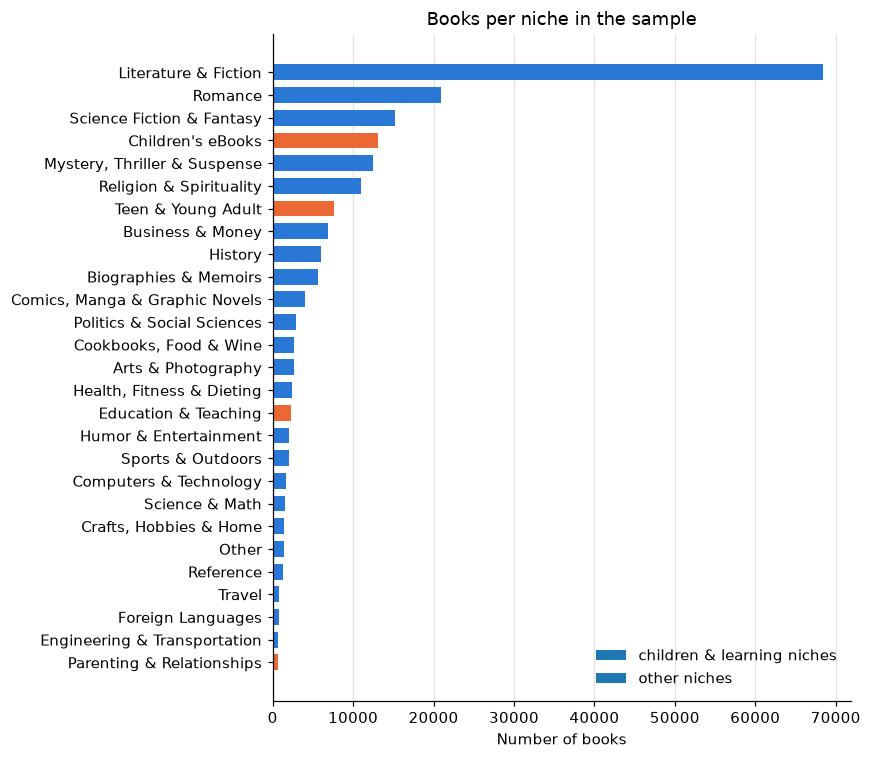

In [27]:
niche_counts = books["niche"].value_counts().sort_values()
colors = [ORANGE if niche in FOCUS_NICHES else BLUE for niche in niche_counts.index]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(niche_counts.index, niche_counts.values, color=colors, height=0.7)
ax.set_title("Books per niche in the sample")
ax.set_xlabel("Number of books")
ax.grid(axis="y", visible=False)
ax.barh([], [], color=ORANGE, label="children & learning niches")
ax.barh([], [], color=BLUE, label="other niches")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Literature & Fiction** is by far the largest niche (about 68,000 of the 198,255 books), followed by Romance,
Science Fiction & Fantasy, Children's eBooks and Mystery. The four children and learning niches (orange) are very different
in size: Children's eBooks has about 13,000 books and Teen & Young Adult about 7,700, while Education & Teaching
(about 2,300) and Parenting & Relationships (about 650) are small.

## Step 15: Which niches are growing?

Demand for a niche is its **share** of all ratings in a year. I use the share, not the count, because the total number of
ratings in the dataset falls every year. 2023 has data only until September, which does not matter for a share.

- `pd.crosstab()` counts how many ratings each niche has in each year.
- `normalize="columns"` turns each year's counts into shares that add up to 100%.

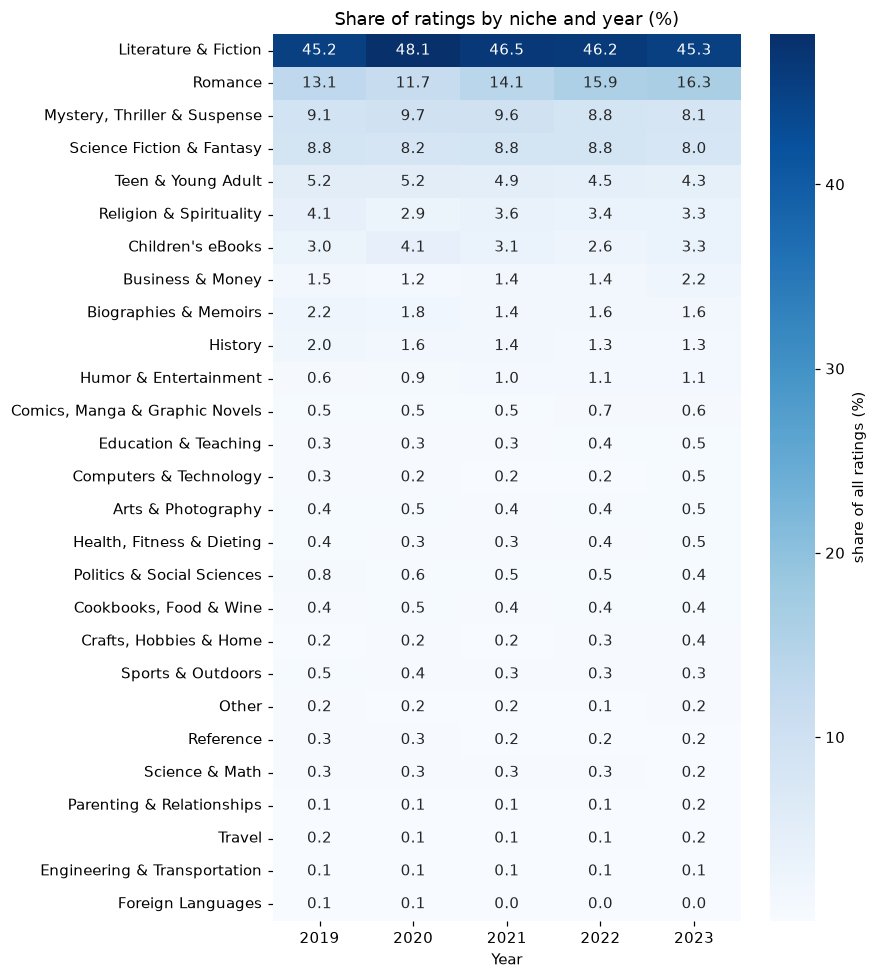

In [28]:
share = pd.crosstab(ratings["niche"], ratings["year"], normalize="columns") * 100
share = share.sort_values(2023, ascending=False)

fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(share, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "share of all ratings (%)"}, ax=ax)
ax.set_title("Share of ratings by niche and year (%)")
ax.set_xlabel("Year")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

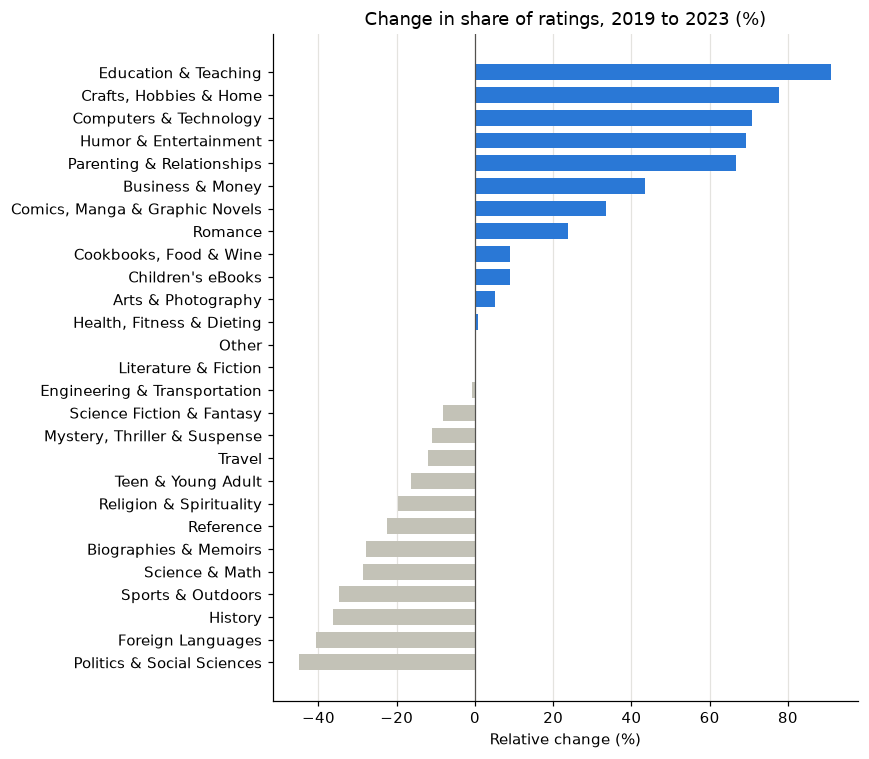

In [29]:
# Change in share from 2019 to 2023, relative to the 2019 share
growth = ((share[2023] - share[2019]) / share[2019] * 100).sort_values()
colors = [BLUE if value > 0 else GREY for value in growth]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(growth.index, growth.values, color=colors, height=0.7)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_title("Change in share of ratings, 2019 to 2023 (%)")
ax.set_xlabel("Relative change (%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- **Literature & Fiction** gets almost half of all ratings every year (45–48%), with no clear trend.
- **Romance** is the large niche that grows most clearly: from 13.1% of all ratings in 2019 to 16.3% in 2023.
- In relative terms the fastest growing niches are small ones: **Education & Teaching** almost doubled its share (+91%),
  followed by Crafts, Computers & Technology, Humor and **Parenting & Relationships** (+67%). Children's eBooks grew a
  little (+9%), while **Teen & Young Adult** lost about 17% of its share.
- History, Politics & Social Sciences and Foreign Languages lose readers' attention.

Small niches have small shares, so their percentages move more from year to year. Growth alone is therefore not enough; in
Notebook 2 I combine it with how open a niche is to less-known authors.

## Step 16: How many ratings does a book get?

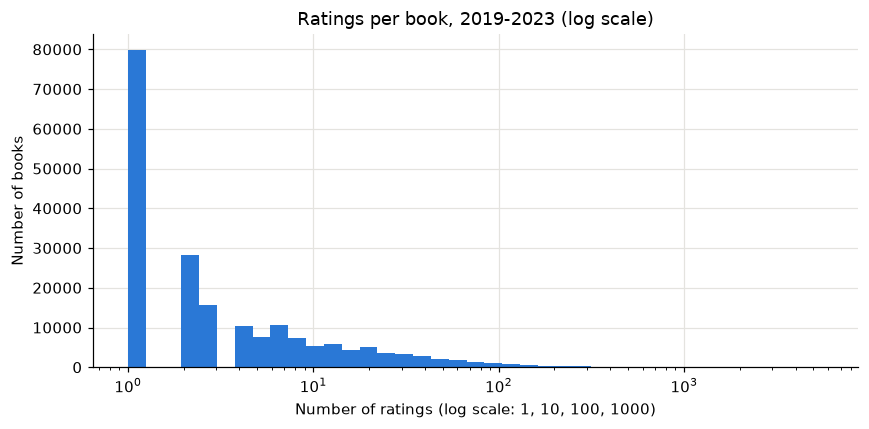

count    198255.0
mean         10.1
std          48.8
min           1.0
25%           1.0
50%           2.0
75%           7.0
max        5643.0
dtype: float64


In [30]:
ratings_per_book = ratings.groupby("parent_asin").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ratings_per_book, bins=np.logspace(0, np.log10(ratings_per_book.max()), 40), color=BLUE)
ax.set_xscale("log")
ax.set_title("Ratings per book, 2019-2023 (log scale)")
ax.set_xlabel("Number of ratings (log scale: 1, 10, 100, 1000)")
ax.set_ylabel("Number of books")
plt.tight_layout()
plt.show()

print(ratings_per_book.describe().round(1))

The number of ratings per book is extremely uneven. Half of the books got **2 ratings or fewer** in almost five
years, and three quarters got 7 or fewer, while the most rated book got **5,643**. The log scale shows this long tail.
Because of it I compare books **within their niche, using percentiles**, and not by raw averages.

## Step 17: Prices and free books by niche

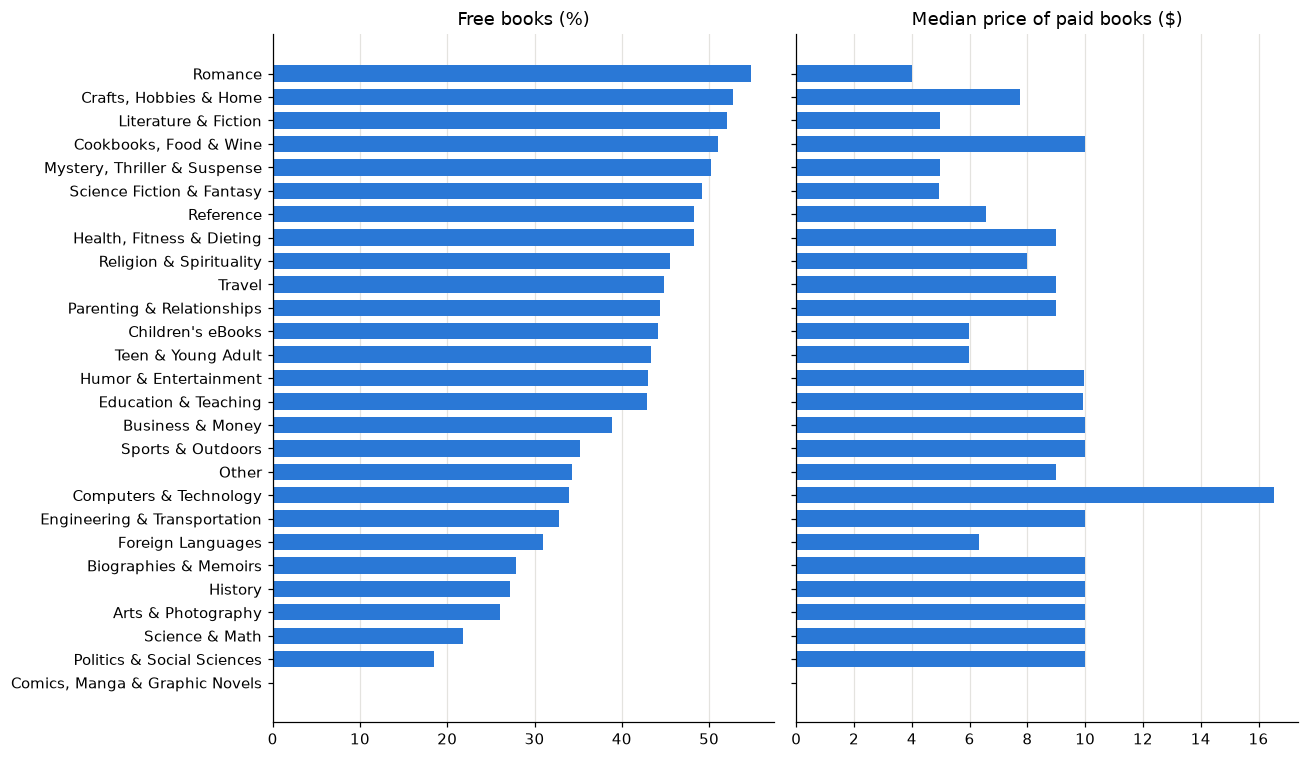

In [31]:
price_by_niche = books.groupby("niche").agg(
    free_share=("price", lambda p: (p == 0).mean() * 100),
    median_paid_price=("price", lambda p: p[p > 0].median()),
).sort_values("free_share")

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
axes[0].barh(price_by_niche.index, price_by_niche["free_share"], color=BLUE, height=0.7)
axes[0].set_title("Free books (%)")
axes[1].barh(price_by_niche.index, price_by_niche["median_paid_price"], color=BLUE, height=0.7)
axes[1].set_title("Median price of paid books ($)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- In every niche a large part of the books is **free**: from about 20% (Politics) to 55% (Romance). Fiction niches,
  especially Romance, use free books most, probably to attract readers to a series.
- Paid books cost about **4–10 dollars** in most niches; Computers & Technology is the most expensive (about 16.5).
- **Comics, Manga & Graphic Novels** has no price at all in the data, which is why its bars are empty. For this niche the
  price cannot be used as a feature.

## Step 18: The audience: verified purchases and review length

Here I test part of my hypothesis about the children and learning niches. I compare, for each niche, how many of the
early reviews come from **verified purchases** and how long the reviews are.

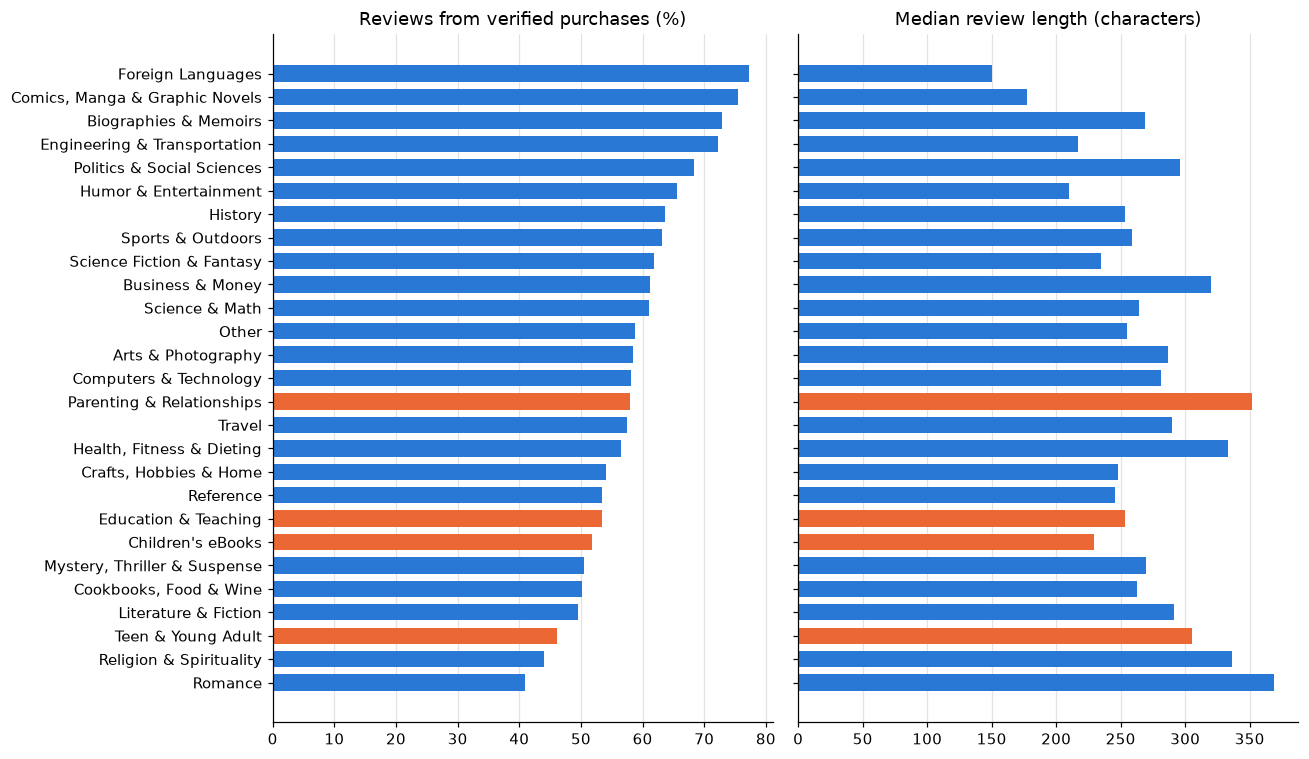

In [32]:
reviews_90["text_length"] = reviews_90["text"].str.len()
audience = reviews_90.groupby("niche").agg(
    verified_share=("verified_purchase", lambda v: v.mean() * 100),
    median_length=("text_length", "median"),
).sort_values("verified_share")
colors = [ORANGE if niche in FOCUS_NICHES else BLUE for niche in audience.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
axes[0].barh(audience.index, audience["verified_share"], color=colors, height=0.7)
axes[0].set_title("Reviews from verified purchases (%)")
axes[1].barh(audience.index, audience["median_length"], color=colors, height=0.7)
axes[1].set_title("Median review length (characters)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- The share of **verified purchases** is lowest in Romance (about 41%), Religion and **Teen & Young Adult** (46%), and
  low in **Children's eBooks** (52%) and **Education & Teaching** (53%). In these niches many readers get the book free
  or through Kindle Unlimited, so their reviews are not marked as purchases.
- Review length differs a lot: **Parenting & Relationships** reviews are among the longest (median about 350 characters),
  while **Children's eBooks** reviews are short (about 230).

So the children and learning niches do not have *more reliable* reviews, measured by verified purchases. Whether they get
*more* reviews per book is part of the features I build next, where every book is compared with its own niche.

## Step 19: Bestsellers as a reference (Kaggle)

The Kaggle dataset has Amazon's bestseller label. I compare bestsellers with the other books on stars, price and Kindle
Unlimited, to see what success looks like at the top of the market.

In [33]:
kaggle = pd.read_csv(RAW / "kindle_data-v2.csv")

bestsellers = kaggle.groupby("isBestSeller").agg(
    books=("asin", "count"),
    median_stars=("stars", "median"),
    median_price=("price", "median"),
    kindle_unlimited_pct=("isKindleUnlimited", lambda k: round(k.mean() * 100, 1)),
).rename(index={False: "other books", True: "bestsellers"})
bestsellers

,books,median_stars,median_price,kindle_unlimited_pct
isBestSeller,,,,
other books,130866,4.5,9.99,26.2
bestsellers,2236,4.5,5.99,65.5


C:\Users\Korisnik\AppData\Local\Temp\ipykernel_20176\3493527909.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, vert=False, showfliers=False, widths=0.5,


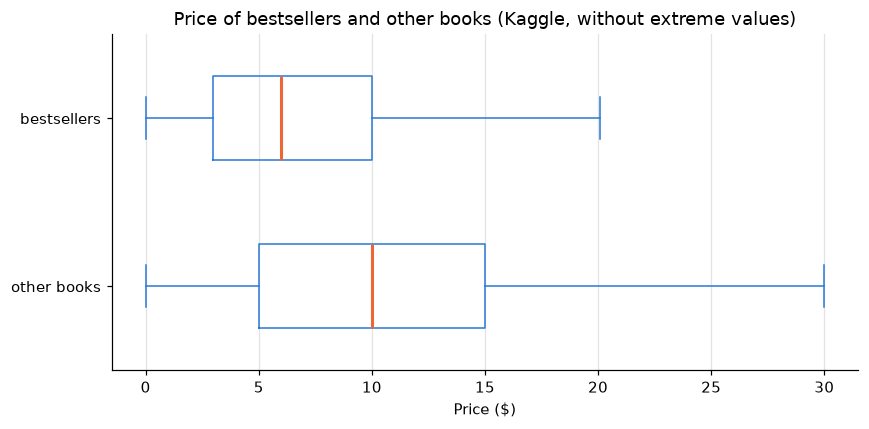

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
data = [kaggle.loc[~kaggle["isBestSeller"], "price"], kaggle.loc[kaggle["isBestSeller"], "price"]]
ax.boxplot(data, vert=False, showfliers=False, widths=0.5,
           medianprops={"color": ORANGE, "linewidth": 2}, boxprops={"color": BLUE}, whiskerprops={"color": BLUE},
           capprops={"color": BLUE})
ax.set_yticks([1, 2], ["other books", "bestsellers"])
ax.set_title("Price of bestsellers and other books (Kaggle, without extreme values)")
ax.set_xlabel("Price ($)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Bestsellers have the **same median rating** as other books (4.5 stars), so stars do not explain success. But they are
**cheaper** (median 5.99 dollars against 9.99) and much more often in **Kindle Unlimited** (65.5% against 26.2%). A low
price and being easy to try seem to matter more than the rating itself. This supports measuring success by the number of
ratings, and using the price and the free indicator as features.